# SPACEc: Distance Permutation Analysis

In [1]:
import spacec as sp

#import standard packages
import os
import pandas as pd
import scanpy as sc

# silencing warnings
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Apply SPACEc publication style to all plots in this notebook
sp.pl.set_style(sp.pl.SPACEcStyle.publication())

In [3]:
# set plotting parameters
sc.settings.set_figure_params(dpi=80, facecolor='white')

In [ ]:
# Specify the path to the data
data_path = "path/to/example_data/raw/"
output_dir = "path/to/output/"
os.makedirs(output_dir, exist_ok=True)

In [5]:
# Load data
adata = sc.read(output_dir + "adata_nn_demo_annotated_cn.h5ad")
adata

AnnData object with n_obs × n_vars = 48457 × 58
    obs: 'DAPI', 'x', 'y', 'area', 'eccentricity', 'perimeter', 'convex_area', 'axis_major_length', 'axis_minor_length', 'region_num', 'unique_region', 'condition', 'unique_cell_id', 'label', 'qc_flag_low_dapi', 'qc_flag_low_size', 'qc_flag_large_size', 'qc_flag_any', 'qc_flag_noise', 'circularity', 'axis_ratio', 'solidity', 'extent', 'n_contacts', 'leiden_1', 'leiden_1_subcluster', 'cell_type_coarse', 'cell_type_coarse_subcluster', 'cell_type_coarse_f', 'cell_type_coarse_f_subcluster', 'cell_type', 'CN_k20_n20', 'CN_k20_n6', 'CN_k20_n6_annot'
    uns: 'CN_k20_n6_colors', 'Centroid_k20_n20', 'Centroid_k20_n6', 'cell_type_coarse_f_subcluster', 'cell_type_coarse_f_subcluster_colors', 'cell_type_coarse_subcluster', 'cell_type_colors', 'clustering_report', 'clustering_tree', 'clustering_tree_ascii', 'leiden_1', 'leiden_1_colors', 'leiden_1_subcluster', 'leiden_1_subcluster_colors', 'masks', 'neighbors', 'umap', 'unique_region_colors'
    obsm

## Identify potential interactions

In [ ]:
# compute the potential interactions
distance_pvals, results_dict = sp.tl.identify_interactions(
    adata = adata, # AnnData object
    cellid = "index", # column that contains the cell id (set index if the cell id is the index of the dataframe)
    x_pos = "x", # x coordinate column
    y_pos = "y", # y coordinate column
    cell_type = "cell_type", # column that contains the cell type information
    region = "unique_region", # column that contains the region information
    num_iterations=1000, # number of iterations for the permutation test
    num_cores=os.cpu_count(),  # number of CPU threads to use
    min_observed = 10, # minimum number of observed interactions to consider a cell type pair
    comparison = 'condition', # column that contains the condition information we want to compare
    distance_threshold=20/0.5085) # distance threshold in px (20 µm)


index is not in the adata.obs, use index as cellid instead!
Computing for observed distances between cell types!


Save triangulation distances output to anndata.uns triDist
Permuting data labels to obtain the randomly distributed distances!
this step can take awhile


In [7]:
# the results_dict contains the results of the permutation test as well as the observed and shuffled distances
results_dict.keys()

dict_keys(['distance_pvals', 'triangulation_distances_observed', 'triangulation_distances_iterated'])

In [8]:
# the distance_pvals contains the p-values for each cell type pair and is automatically added to the adata.uns
adata.uns['triDist']

,unique_region,celltype1_index,celltype1,celltype1_X,celltype1_Y,celltype2_index,celltype2,celltype2_X,celltype2_Y,distance,condition
0,reg001,reg001_1,M1 Macrophage,1532.957529,166.227799,reg001_4,Plasma cell,1519.340807,164.730942,13.698748,tonsil
1,reg001,reg001_1,M1 Macrophage,1532.957529,166.227799,reg001_7,CD8+ T cell,1544.411765,165.151261,11.504714,tonsil
2,reg001,reg001_1,M1 Macrophage,1532.957529,166.227799,reg001_37,Vessel,1527.188406,180.818841,15.690165,tonsil
3,reg001,reg001_1,M1 Macrophage,1532.957529,166.227799,reg001_38,GCB,1547.287449,184.485830,23.209961,tonsil
4,reg001,reg001_2,Neutrophil,1463.404348,163.765217,reg001_3,Neutrophil,1486.888889,162.546296,23.516153,tonsil
...,...,...,...,...,...,...,...,...,...,...,...
131191,reg002,reg002_23054,Epithelial cell,1365.537313,2527.522388,reg002_23046,Epithelial cell,1331.966790,2522.726937,33.911302,tonsillitis
131192,reg002,reg002_23051,Epithelial cell,1420.297521,2524.975207,reg002_23047,Epithelial cell,1382.323077,2522.630769,38.046744,tonsillitis
131193,reg002,reg002_23054,Epithelial cell,1365.537313,2527.522388,reg002_23047,Epithelial cell,1382.323077,2522.630769,17.483987,tonsillitis
131194,reg002,reg002_23054,Epithelial cell,1365.537313,2527.522388,reg002_23049,Plasma cell,1350.275510,2523.020408,15.911960,tonsillitis


In [9]:
# save adata
adata.write(output_dir + "adata_nn_demo_annotated_cn.h5ad")

## Filter for most significant results

In this example the results are filtered twice. First to remove rare cell types from the analysis because they are overrepresented when comparing distances, and then we filter on statistical significance as well as absolute log fold change.

In [10]:
distance_pvals_filt = sp.tl.remove_rare_cell_types(adata, 
                       distance_pvals, 
                       cell_type_column="cell_type", 
                       min_cell_type_percentage=1)

Cell types that belong to less than 1% of total cells:
['Neutrophil', 'Mast cell', 'NK cell']
Categories (16, object): ['B cell', 'CD4+ T cell', 'CD8+ T cell', 'DC', ..., 'Treg', 'Unresolved', 'Vessel', 'cDC1']


In [11]:
# Identify significant cell-cell interactions
# dist_table_filt is a simplified table used for plotting
# dist_data_filt contains the filtered raw data with more information about the pairs
# The function outputs two dataframes: dist_data_filt contains all filtered interactions, and dist_table_filt contains a table of all interactions that show a significant value in both tissues
dist_table_filt, dist_data_filt = sp.tl.filter_interactions(
    distance_pvals = distance_pvals_filt,
    pvalue = 0.05,
    logfold_group_abs = 0.1,
    comparison = 'condition')

print(dist_table_filt.shape)
dist_data_filt

(59, 2)


,celltype1,celltype2,condition,expected,expected_mean,keep_x,observed,observed_mean,keep_y,pvalue,logfold_group,interaction,logfold_group_abs,pairs
4,B cell,CD8+ T cell,tonsil,"[17.59384920445273, 18.153755744661634, 17.600...",17.853911,True,"[35.24327891038194, 13.709758502704554, 14.591...",17.057072,True,2.283667e-38,-0.065870,B cell --> CD8+ T cell,0.065870,B cell_CD8+ T cell
5,B cell,CD8+ T cell,tonsillitis,"[18.32829852842, 17.408039534920054, 17.209178...",17.268901,True,"[14.757990562865526, 16.65689203037669, 13.602...",15.624207,True,2.230804e-86,-0.144393,B cell --> CD8+ T cell,0.144393,B cell_CD8+ T cell
28,B cell,Vessel,tonsil,"[17.846009371340777, 18.20619916492107, 17.754...",17.871417,True,"[16.84663149959558, 34.73214500181831, 9.61257...",17.206974,True,6.947562e-32,-0.054661,B cell --> Vessel,0.054661,B cell_Vessel
29,B cell,Vessel,tonsillitis,"[17.028178799303312, 17.068117109443367, 16.58...",17.290755,True,"[15.587565899170984, 17.148249129339224, 9.327...",15.925078,True,5.697297e-56,-0.118700,B cell --> Vessel,0.118700,B cell_Vessel
32,CD4+ T cell,B cell,tonsil,"[17.472010234823156, 17.396876364144507, 17.37...",17.592905,True,"[18.13568036380469, 15.761148730891112, 13.943...",16.993952,True,5.966618e-37,-0.049972,CD4+ T cell --> B cell,0.049972,CD4+ T cell_B cell
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
489,cDC1,Epithelial cell,tonsillitis,"[16.83625999083935, 17.09407518494526, 16.3859...",17.219061,True,"[17.972546903925345, 22.2555106084274, 21.2110...",19.181884,True,2.660181e-03,0.155738,cDC1 --> Epithelial cell,0.155738,cDC1_Epithelial cell
492,cDC1,M1 Macrophage,tonsil,"[16.776861728819405, 16.574937691312385, 16.14...",17.621089,True,"[15.004417557491253, 11.589597246839988, 16.70...",15.279604,True,1.724406e-04,-0.205696,cDC1 --> M1 Macrophage,0.205696,cDC1_M1 Macrophage
493,cDC1,M1 Macrophage,tonsillitis,"[17.89326178233444, 21.253133753939693, 15.585...",17.026350,True,"[23.051440359748053, 20.22770638063554, 13.612...",17.824424,True,6.100872e-02,0.066086,cDC1 --> M1 Macrophage,0.066086,cDC1_M1 Macrophage
504,cDC1,Treg,tonsil,"[19.017080349160278, 16.75799959070342, 19.337...",17.781848,True,"[13.272141854078766, 11.002279535302318, 15.79...",16.229176,True,1.111847e-03,-0.131815,cDC1 --> Treg,0.131815,cDC1_Treg


## Visualization

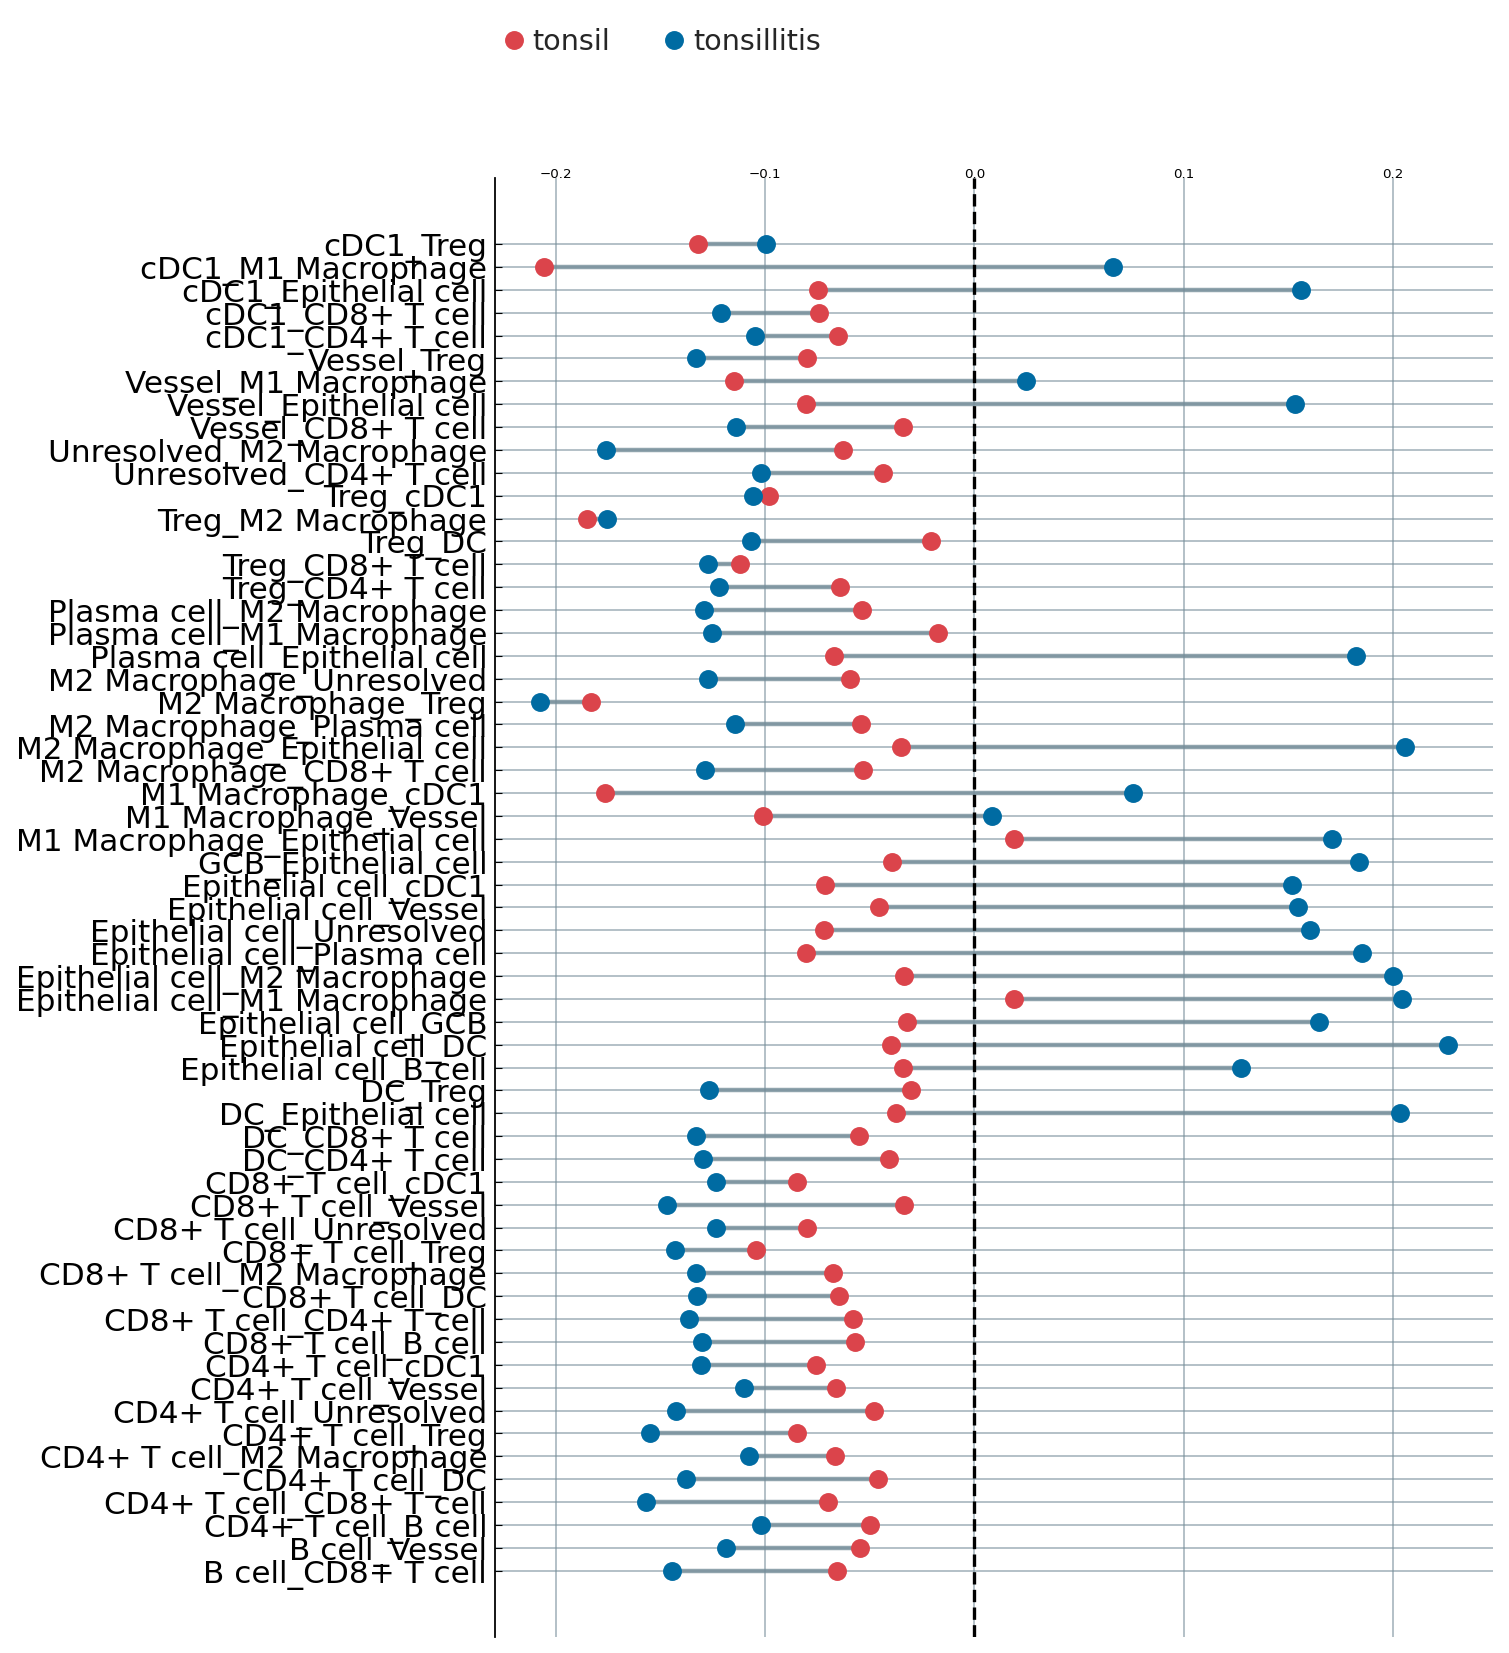

In [13]:
sp.pl.dumbbell(data = dist_table_filt, figsize=(8,12), colors = ['#DB444B', '#006BA2'])

(118, 13)


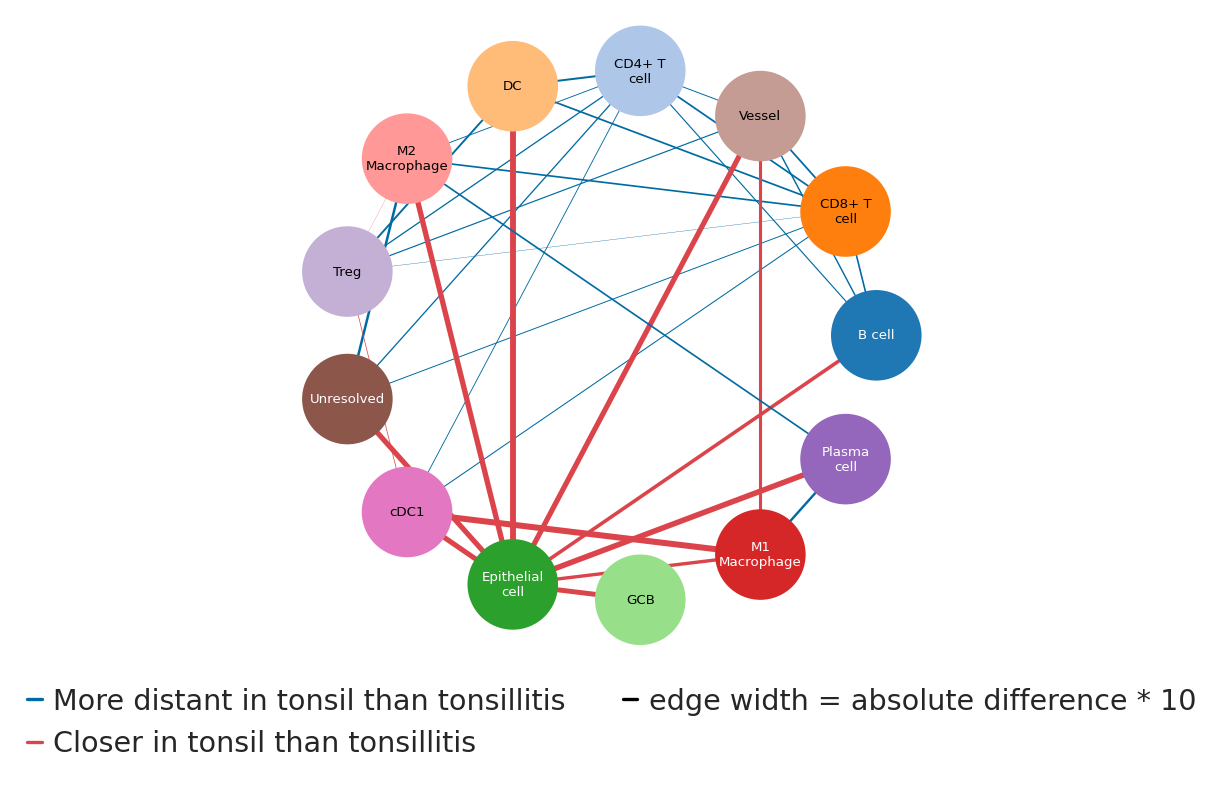

In [14]:
sp.pl.distance_graph(dist_table = dist_data_filt, # the (filtered) distance data table you want to plot 
                  distance_pvals = distance_pvals, # the full distance data table
                  condition_pair=['tonsil', 'tonsillitis'],
                  node_size=1600, font_size=6,
                  palette=None,
                  dpi = 600,
                  savefig=False,
                  output_fname="",
                  output_dir=output_dir,)